In [6]:
import pandas as pd
import numpy as np


def load_table(path):
    path = str(path)
    if path.lower().endswith(('.csv',)):
        return pd.read_csv(path)
    elif path.lower().endswith(('.xls', '.xlsx')):
        return pd.read_excel(path)
    else:
        raise ValueError(f"Unsupported extension for {path}. Use .csv, .xls, or .xlsx")


def describe_col_type(series):
    s = series.rename('v')
    non_null = s.dropna()
    if non_null.empty:
        return 'x_nan'  # only nan/None values

    # numeric conversion check
    numeric = pd.to_numeric(non_null, errors='coerce')
    is_numeric = numeric.notna().all()

    if is_numeric:
        # check integerness of numeric values
        if np.all(np.floor(numeric) == numeric):
            return 'x_int'
        else:
            return 'x'

    # non-numeric at all -> string category/label
    return 'x_str'


def make_descriptor_encoding(desc_df, key='SMILES'):
    enc = {}
    x_i = 0
    x_str_j = 0
    x_nan_k = 0
    x_int_m = 0

    for col in desc_df.columns:
        if col == key:
            continue
        col_type = describe_col_type(desc_df[col])

        if col_type == 'x':
            enc[col] = f'x_{x_i}'
            x_i += 1
        elif col_type == 'x_str':
            enc[col] = f'x_str_{x_str_j}'
            x_str_j += 1
        elif col_type == 'x_nan':
            enc[col] = f'x_nan_{x_nan_k}'
            x_nan_k += 1
        elif col_type == 'x_int':
            enc[col] = f'x_int_{x_int_m}'
            x_int_m += 1
        else:
            enc[col] = f'x_unknown_{col}'

    return enc


def merge_descriptor_target(desc_path, target_path, key_target='SMILES', key_descriptor='SMILES'):
    desc_df = load_table(desc_path)
    target_df = load_table(target_path)

    if key_descriptor not in desc_df.columns:
        raise KeyError(f"Key '{key_descriptor}' not found in descriptor file")
    if key_target not in target_df.columns:
        raise KeyError(f"Key '{key_target}' not found in target file")

    desc_smiles = set(desc_df[key_descriptor].dropna().astype(str))
    target_smiles = set(target_df[key_target].dropna().astype(str))
    missing_from_desc = sorted(target_smiles - desc_smiles)
    if missing_from_desc:
        print(f"Warning: {len(missing_from_desc)} SMILES entries in target are missing from descriptor file and will be dropped in merged_df:")
        for s in missing_from_desc[:20]:
            print(f"  - {s}")
        if len(missing_from_desc) > 20:
            print(f"  ... and {len(missing_from_desc)-20} more")

    merged = pd.merge(desc_df, target_df, left_on=key_descriptor, right_on=key_target, how='inner')
    encoding = make_descriptor_encoding(desc_df, key=key_descriptor)

    return merged, encoding

In [4]:
df = pd.read_csv('20260422_LNiH2_library_001_to_download_2026_03_24_descriptors_.csv')
df.columns

Index(['%Vbur_atom_C1_radius_3.0_boltz', '%Vbur_atom_C1_radius_4.5_max',
       '%Vbur_atom_C1_radius_5.0_lowE', '%Vbur_atom_C1_radius_5.0_boltz',
       '%Vbur_atom_C2_radius_2.5_min', '%Vbur_atom_C2_radius_2.5_boltz',
       '%Vbur_atom_C2_radius_3.5_max', '%Vbur_atom_C2_radius_3.5_lowE',
       '%Vbur_atom_C2_radius_5.0_boltz', '%Vbur_atom_H1_radius_2.0_min',
       ...
       'dipole_z_Ni-N2-N1_min', 'dipole_z_Ni-N2-N1_max',
       'dipole_z_Ni-N2-N1_lowE', 'dipole_z_Ni-N2-N1_boltz',
       'angle_H2-Ni-H1_min', 'angle_H2-Ni-H1_boltz', 'smiles', 'inchi',
       'inchi_folder', 'ligand_class'],
      dtype='object', length=506)

In [7]:
merged_df, encoding = merge_descriptor_target('20260422_LNiH2_library_001_to_download_2026_03_24_descriptors_.csv', 
                                              'experiment_data_ee.xlsx',
                                              key_descriptor='inchi',
                                              key_target='INCHI')


In [8]:
from mlr_utils.feature_selection import auto_feature_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor


# Choose the target column name from target dataset (adjust to your target's actual name)
target_col = 'ΔΔG'  # update as needed for your target column

# Exhaustive search for the best descriptor combinations.
# This will evaluate subset sizes [1,2,3] by default for speed.
result = auto_feature_selection(
    merged_df,
    target_col=target_col,
    key='INCHI',
    selection_mode='sfs',
    direction='forward',
    n_features_to_select=[2],
    split_method='y_equidistant',
    random_state=42,
    scoring='r2',
    model=[ LinearRegression() ],
    max_combinations=20000,
    n_jobs=-1,
    corr_threshold=0.9,  # remove highly correlated features before selection
    exclude_cols=['yield', 'ee', 'Unnamed: 3'],
    print_ml_equation=True,
    top_k=10
)

print(result['mlr_info'])

/Users/julesschleinitz/Desktop/Code/orca_descriptors/mlr_utils/feature_selection.py:301: UserWarning: Number of combinations for k=2 is 20910 > max_combinations=20000. Continuing evaluation of all combinations; this may take a long time. To limit runtime, reduce n_features_to_select or set max_combinations smaller.
  warnings.warn(


k=2 combos:   0%|          | 0/20910 [00:00<?, ?combo/s]


MLR equation:
ΔΔG = 51.0347 + (-0.1938 * %Vbur_atom_H1_radius_2.0_lowE) + (-75.5489 * nao_Ni_Val-4s_occupancy_boltz)

MLR parameters:
  %Vbur_atom_H1_radius_2.0_lowE: -0.193763
  nao_Ni_Val-4s_occupancy_boltz: -75.548898
intercept: 51.034675
{'model': LinearRegression(), 'intercept': 51.034674991455965, 'coefs': array([ -0.19376314, -75.54889849]), 'features': ['%Vbur_atom_H1_radius_2.0_lowE', 'nao_Ni_Val-4s_occupancy_boltz'], 'equation': 'ΔΔG = 51.0347 + (-0.1938 * %Vbur_atom_H1_radius_2.0_lowE) + (-75.5489 * nao_Ni_Val-4s_occupancy_boltz)', 'r2': 0.5240855373467392}


In [9]:
top_10 = result['top']
for rank, item in enumerate(top_10, 1):
    print(rank, f"| # of desc:", item['n_features'], "| R2 train :", round(item['train_score'], 2), "| R2 validation :", round(item['val_score'], 2), "| Features :", item['features'])

1 | # of desc: 2 | R2 train : 0.53 | R2 validation : 0.43 | Features : ['%Vbur_atom_H1_radius_2.0_lowE', 'nao_Ni_Val-4s_occupancy_boltz']
2 | # of desc: 2 | R2 train : 0.5 | R2 validation : 0.37 | Features : ['chelpG_Ni_min', 'nao_Ni_Val-4s_occupancy_boltz']
3 | # of desc: 2 | R2 train : 0.48 | R2 validation : 0.37 | Features : ['Angle_Ni_N2_C2_min', 'Sterimol_C1_N1_L_min']
4 | # of desc: 2 | R2 train : 0.48 | R2 validation : 0.37 | Features : ['Angle_Ni_N2_C2_min', 'Sterimol_C1_N1_L_min']
5 | # of desc: 2 | R2 train : 0.5 | R2 validation : 0.36 | Features : ['%Vbur_atom_Ni_radius_2.5_min', 'Dihed_C1_C2_N2_Ni_max']
6 | # of desc: 2 | R2 train : 0.5 | R2 validation : 0.36 | Features : ['mulliken_Ni_max', 'loewdin_Ni_max']
7 | # of desc: 2 | R2 train : 0.51 | R2 validation : 0.35 | Features : ['%Vbur_atom_C2_radius_2.5_min', '%Vbur_atom_Ni_radius_2.5_min']
8 | # of desc: 2 | R2 train : 0.52 | R2 validation : 0.35 | Features : ['Angle_Ni_N2_C2_min', 'loewdin_Ni_min']
9 | # of desc: 2 | R2


MLR equation:
ΔΔG = 51.0347 + (-0.1938 * %Vbur_atom_H1_radius_2.0_lowE) + (-75.5489 * nao_Ni_Val-4s_occupancy_boltz)

MLR parameters:
  %Vbur_atom_H1_radius_2.0_lowE: -0.193763
  nao_Ni_Val-4s_occupancy_boltz: -75.548898
intercept: 51.034675
R2 (full data fit): 0.5241


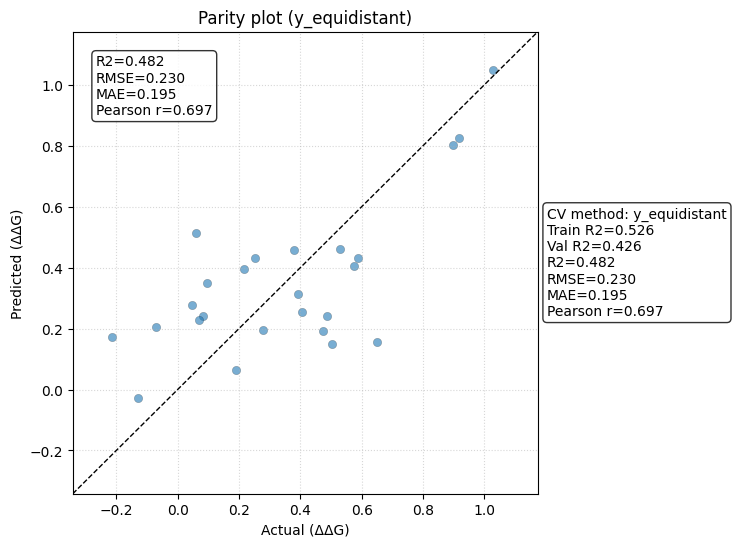

In [10]:
from mlr_utils.plot_utils import plot_result_parity

fig, ax, metrics, split_stats = plot_result_parity(
    merged_df,
    target_col=target_col,
    features=result['best']['features'],
    model=LinearRegression(),
    split_method='y_equidistant',
    cv=5,
)

In [11]:
from mlr_utils.plot_utils import bokeh_parity_with_tooltips
from sklearn.linear_model import LinearRegression

p = bokeh_parity_with_tooltips(
    merged_df,
    target_col='ΔΔG',
    features=result['best']['features'],
    model=LinearRegression(),
    cv=5,
    split_method='y_equidistant',
    inchi_col='INCHI'
)

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

[15:56:18] ERROR: 

